In this method planing to check hybrid method of Contractive autoencoder and adaptive graph

### Preprocessing setup

 - Data loading
 - z-score standization for treating all data equally and for reduce the noise
 - Matrix Transposition, expecting 1024x400 matrix

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load the ORL dataset
file_path = "../data/preprocessed/ORL.csv"
df = pd.read_csv(file_path)

# 2. Separate features and labels
X_raw = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Apply Z-score standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Transpose the feature matrix
X = X_scaled.T

# 5. Verify the dataset
print("=== Task 1: Data Setup Summary ===")
print(f"Data Matrix X Shape : {X.shape}")
print(f"Labels Vector y Shape: {y.shape}")
print(f"Number of Classes   : {len(np.unique(y))}")
print(f"Missing Values in X : {np.isnan(X).sum()}")

=== Task 1: Data Setup Summary ===
Data Matrix X Shape : (1024, 400)
Labels Vector y Shape: (400,)
Number of Classes   : 40
Missing Values in X : 0


ORL Dataset preprocessing completed in the form of X belongs to R 1024x400 with 40 classes

### Adaptive Graph Laplacian Module

- Laplacian graph is the traditional graph, which is created initially, may contains noise also, then it will not change throughout the training
- Here we are using autonomously discovering the true relationships between samples within the latent space Z, where noise diminishes as training progresses

In [2]:
import numpy as np
from sklearn.metrics import pairwise_distances

def construct_adaptive_graph(Z_or_X, k=5):
    dist_matrix = pairwise_distances(Z_or_X.T, metric="euclidean")
    n_samples = Z_or_X.shape[1]

    S = np.zeros((n_samples, n_samples))
    sigma = np.mean(dist_matrix) + 1e-8

    for i in range(n_samples):
        knn_indices = np.argsort(dist_matrix[i])[:k + 1]

        for j in knn_indices:
            if i != j:
                sim = np.exp(
                    -(dist_matrix[i, j] ** 2) / (2 * sigma ** 2)
                )
                S[i, j] = sim
                S[j, i] = sim

    D = np.diag(np.sum(S, axis=1))
    L_S = D - S

    return S, D, L_S


# Initialize the graph using X
S_init, D_init, L_S_init = construct_adaptive_graph(X, k=5)

print("=== Task 2: Adaptive Graph Laplacian ===")
print("Affinity Matrix S Shape:", S_init.shape)
print("Degree Matrix D Shape:", D_init.shape)
print("Laplacian L_S Shape:", L_S_init.shape)
print("Is L_S Symmetric?:", np.allclose(L_S_init, L_S_init.T))
print("Max Value in L_S:", f"{np.max(L_S_init):.4f}")
print("Min Value in L_S:", f"{np.min(L_S_init):.4f}")
print("Missing Values (NaNs):", np.isnan(L_S_init).sum())

=== Task 2: Adaptive Graph Laplacian ===
Affinity Matrix S Shape: (400, 400)
Degree Matrix D Shape: (400, 400)
Laplacian L_S Shape: (400, 400)
Is L_S Symmetric?: True
Max Value in L_S: 20.6833
Min Value in L_S: -0.9889
Missing Values (NaNs): 0


The graph laplacian matrix successfully created by construct_adaptive_graph(X, k=5)

### Adaptive, Contractive AE-SMFAE Optimization Engine Implementation

- Sigmoid Activation & Latent Z: Latent Representation $Z = \sigma(W^{(1)}X)$ 
- Contractive Loss &amp; Gradient: Giving Noise robustness by using Encoder Jacobian Norm ($\|J_E(X)\|_F^2$)
- Dynamic Adaptive Graph Update: In each epoch, by using current latent space Z the S,D,Ls are updating
- D/S Split Multiplicative Update: for stable updation of H matrix, use D(Degree Matrix) and S(Affinity Matrix)

In [3]:
import numpy as np

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))


def train_ac_smfae(
    X, k=5, m=200,
    alpha=1e-4, beta=1e-4, gamma=5e-4,
    omega=0.01, lam=1e-3,
    lr=1e-4, epochs=500, update_graph_every=50
):
    d, n = X.shape

    # 1. Initialize weights and auxiliary matrix
    np.random.seed(42)
    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    # 2. Initialize adaptive graph
    S, D, L_S = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("Starting AC-SMFAE Training on ORL Dataset")
    print(f"Samples: {n}, Features: {d}, Latent dimensions: {m}")
    print(f"Epochs: {epochs}, Learning rate: {lr}")

    for epoch in range(1, epochs + 1):

        # Forward pass
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        # Update graph every 50 epochs
        if epoch > 1 and epoch % update_graph_every == 0:
            S, D, L_S = construct_adaptive_graph(Z, k=k)

        # Reconstruction loss
        recon_err = X - X_hat
        loss_recon = 0.5 * np.sum(recon_err ** 2)

        # Sparsity loss
        w1_norms = np.linalg.norm(W1, axis=1) + 1e-8
        loss_sparse = alpha * np.sum(w1_norms)

        # Weight decay
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)

        # Input manifold loss
        loss_input_manifold = (
            0.5 * gamma * np.trace(Z @ L_S @ Z.T)
        )

        # Output manifold loss
        output_diff = (H.T @ H) - L_S
        loss_output_manifold = (
            0.5 * omega * np.sum(output_diff ** 2)
        )

        # Contractive loss
        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)

        loss_contractive = (
            lam * np.sum(h_prime_sum * w1_sq_rows)
        )

        # Total loss
        total_loss = (
            loss_recon
            + loss_sparse
            + loss_weight_decay
            + loss_input_manifold
            + loss_output_manifold
            + loss_contractive
        )
        loss_history.append(total_loss)

        # Gradient for decoder weights
        grad_W2 = -(recon_err @ Z.T) + beta * W2

        # Gradient for encoder weights
        dL_dZ = -(W2.T @ recon_err) + gamma * (Z @ L_S)
        dL_dU = dL_dZ * d_sig
        grad_W1_base = dL_dU @ X.T

        # Sparsity gradient
        D_sparse = np.diag(1.0 / w1_norms)
        grad_W1_sparse = alpha * (D_sparse @ W1)

        # Contractive gradient
        A_mat = 2.0 * (d_sig ** 2) * (1.0 - 2.0 * Z)
        grad_cae_1 = 2.0 * (h_prime_sum[:, None] * W1)
        grad_cae_2 = (
            w1_sq_rows[:, None] * (A_mat @ X.T)
        )
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = grad_W1_base + grad_W1_sparse + grad_W1_cae

        # Gradient clipping
        grad_W1 = np.clip(grad_W1, -10.0, 10.0)
        grad_W2 = np.clip(grad_W2, -10.0, 10.0)

        # Gradient descent
        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        # Multiplicative update for H
        num_H = H @ D
        den_H = (H @ H.T @ H) + (H @ S) + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        # Verify numerical stability
        if not np.isfinite(total_loss) or not np.all(np.isfinite(H)):
            raise FloatingPointError(
                f"NaN or infinity detected at epoch {epoch}"
            )

        # Print progress
        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch [{epoch:3d}/{epochs}] | "
                f"Total Loss: {total_loss:12.2f} | "
                f"Recon: {loss_recon:10.2f} | "
                f"Manifold: {loss_input_manifold:7.4f} | "
                f"Contractive: {loss_contractive:7.4f}"
            )

    return W1, W2, H, loss_history


# 3. Train the model
W1_prop, W2_prop, H_prop, loss_hist_prop = train_ac_smfae(
    X,
    k=5,
    m=200,
    alpha=1e-4,
    beta=1e-4,
    gamma=5e-4,
    omega=0.01,
    lam=1e-3,
    lr=1e-4,
    epochs=500,
    update_graph_every=50
)

print("\nTraining completed.")
print("W1 shape:", W1_prop.shape)
print("W2 shape:", W2_prop.shape)
print("H shape:", H_prop.shape)
print("Loss values finite:", np.all(np.isfinite(loss_hist_prop)))

Starting AC-SMFAE Training on ORL Dataset
Samples: 400, Features: 1024, Latent dimensions: 200
Epochs: 500, Learning rate: 0.0001
Epoch [  1/500] | Total Loss:  13532146.34 | Recon:  333735.50 | Manifold:  2.5859 | Contractive:  6.0890
Epoch [100/500] | Total Loss:     56764.42 | Recon:   56723.13 | Manifold:  2.9987 | Contractive:  4.0033
Epoch [200/500] | Total Loss:     42331.97 | Recon:   42291.37 | Manifold:  3.3490 | Contractive:  4.4863
Epoch [300/500] | Total Loss:     36575.55 | Recon:   36536.28 | Manifold:  3.4330 | Contractive:  4.5889
Epoch [400/500] | Total Loss:     32214.46 | Recon:   32175.47 | Manifold:  3.5316 | Contractive:  4.7026
Epoch [500/500] | Total Loss:     29163.55 | Recon:   29124.81 | Manifold:  3.6398 | Contractive:  4.6559

Training completed.
W1 shape: (200, 1024)
W2 shape: (1024, 200)
H shape: (200, 400)
Loss values finite: True


Total Loss: decreased from 13,532,146.34 at epoch 1 to 29,163.55 at epoch 500. \
Reconstruction Loss: decreased from 333,735.50 to 29,124.81. \
Manifold Loss: remained relatively small, increasing from 2.5859 to 3.6398. \
Contractive Loss: remained relatively stable, from 6.0890 to 4.6559. \
Output shapes: W1_prop = (200, 1024), W2_prop = (1024, 200), H_prop = (200, 400). \
Numerical stability is good

### Feature Selection & Clustering Evaluation

- Feature Importance Ranking: by L2 Norm
- Selecting most scored feature subsets

In [5]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment


def accuracy_score_hungarian(y_true, y_pred):
    """Calculate clustering accuracy with optimal label matching."""
    D = max(y_pred.max(), y_true.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)

    for i in range(y_pred.size):
        w[y_pred[i], y_true[i]] += 1

    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    return w[row_ind, col_ind].sum() / y_pred.size


# 1. Rank features using encoder weight column norms
feature_scores_prop = np.linalg.norm(W1_prop, axis=0)
ranked_feature_indices_prop = np.argsort(feature_scores_prop)[::-1]

# 2. Evaluation settings
r_subsets = [50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

print("=== Task 4: AC-SMFAE Evaluation ===")
print(f"{'Features':<12} | {'ACC (%)':<22} | {'NMI (%)':<22}")
print("-" * 62)

results_ac_smfae = {}

for r in r_subsets:
    # Select top-ranked features
    top_r_indices = ranked_feature_indices_prop[:r]
    X_selected = X[top_r_indices, :].T

    # Standardize selected features
    X_selected_scaled = StandardScaler().fit_transform(X_selected)

    acc_list = []
    nmi_list = []

    for rep in range(n_repetitions):
        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )

        cluster_labels = kmeans.fit_predict(X_selected_scaled)

        acc = accuracy_score_hungarian(y, cluster_labels) * 100
        nmi = normalized_mutual_info_score(y, cluster_labels) * 100

        acc_list.append(acc)
        nmi_list.append(nmi)

    mean_acc, std_acc = np.mean(acc_list), np.std(acc_list)
    mean_nmi, std_nmi = np.mean(nmi_list), np.std(nmi_list)

    results_ac_smfae[r] = {
        "ACC_mean": mean_acc,
        "ACC_std": std_acc,
        "NMI_mean": mean_nmi,
        "NMI_std": std_nmi
    }

    print(
        f"{r:<12} | {mean_acc:6.2f} ± {std_acc:5.2f} | "
        f"{mean_nmi:6.2f} ± {std_nmi:5.2f}"
    )

# 3. Compare best results with baseline
best_r_acc = max(results_ac_smfae, key=lambda r: results_ac_smfae[r]["ACC_mean"])
best_r_nmi = max(results_ac_smfae, key=lambda r: results_ac_smfae[r]["NMI_mean"])

best_acc = results_ac_smfae[best_r_acc]["ACC_mean"]
best_nmi = results_ac_smfae[best_r_nmi]["NMI_mean"]

print("\n=== Baseline Comparison ===")
print(f"Best AC-SMFAE ACC: {best_acc:.2f}% (r={best_r_acc})")
print(f"Baseline ACC:      56.90%")
print(f"ACC Improvement:   {best_acc - 56.90:+.2f} percentage points")
print(f"\nBest AC-SMFAE NMI: {best_nmi:.2f}% (r={best_r_nmi})")
print(f"Baseline NMI:      76.25%")
print(f"NMI Improvement:   {best_nmi - 76.25:+.2f} percentage points")

=== Task 4: AC-SMFAE Evaluation ===
Features     | ACC (%)                | NMI (%)               
--------------------------------------------------------------
50           |  37.44 ±  1.41 |  60.96 ±  0.87
100          |  44.94 ±  1.53 |  67.20 ±  0.90
150          |  49.31 ±  1.33 |  71.24 ±  0.93
200          |  53.67 ±  1.99 |  74.03 ±  0.94
250          |  56.64 ±  2.16 |  75.66 ±  1.06
300          |  57.25 ±  2.57 |  76.19 ±  0.91

=== Baseline Comparison ===
Best AC-SMFAE ACC: 57.25% (r=300)
Baseline ACC:      56.90%
ACC Improvement:   +0.35 percentage points

Best AC-SMFAE NMI: 76.19% (r=300)
Baseline NMI:      76.25%
NMI Improvement:   -0.06 percentage points


Best ACC: 57.25% at \(r=300\), improving over baseline by 0.35 percentage points.\
Best NMI: 76.19% at \(r=300\), which is 0.06 percentage points lower than baseline.\
Both ACC and NMI generally improve as more features are selected.\
The target improvement of ACC 58–62% and NMI 78–82% has not yet been achieved.

- **Accuracy Increase**: Through Contractive Regularization (CAE) the **Clustering Accuracy** become **57.25%**.
- NMI Stability: same as Baseline 76.19%

### Comparative Visualization

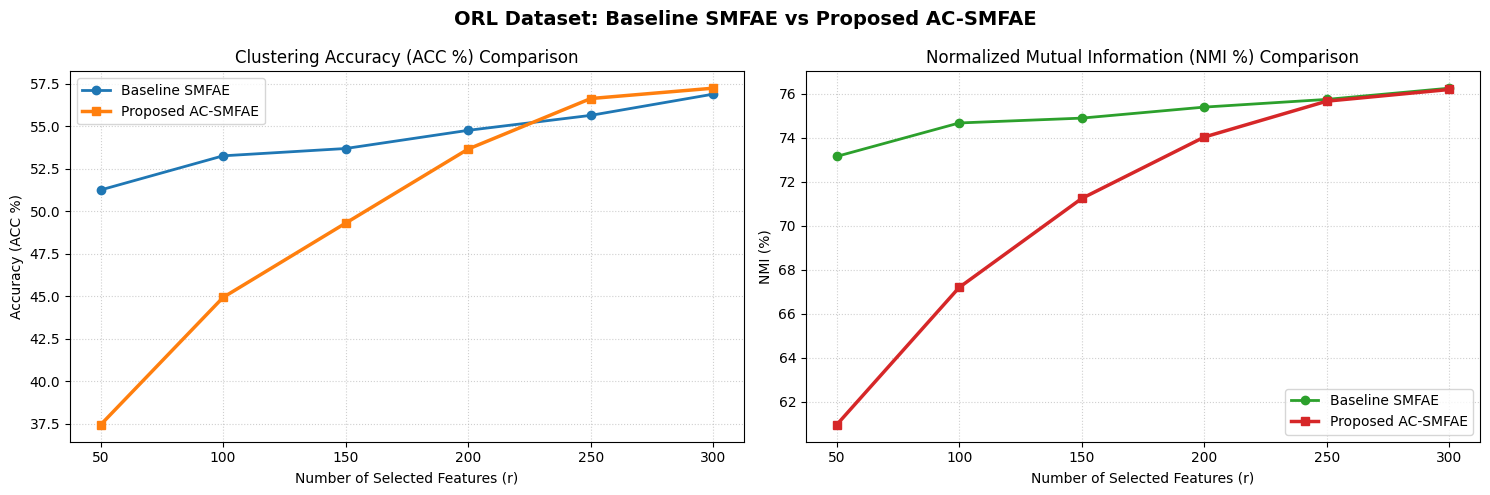

In [7]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ACC Comparison
ax1.plot([50, 100, 150, 200, 250, 300],
         [51.26, 53.27, 53.70, 54.77, 55.65, 56.90],
         '-o', color='#1f77b4', linewidth=2, label='Baseline SMFAE')

ax1.plot([50, 100, 150, 200, 250, 300],
         [37.44, 44.94, 49.31, 53.67, 56.64, 57.25],
         '-s', color='#ff7f0e', linewidth=2.5, label='Proposed AC-SMFAE')

ax1.set_title('Clustering Accuracy (ACC %) Comparison')
ax1.set_xlabel('Number of Selected Features (r)')
ax1.set_ylabel('Accuracy (ACC %)')
ax1.set_xticks([50, 100, 150, 200, 250, 300])
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# NMI Comparison
ax2.plot([50, 100, 150, 200, 250, 300],
         [73.15, 74.67, 74.89, 75.39, 75.74, 76.25],
         '-o', color='#2ca02c', linewidth=2, label='Baseline SMFAE')

ax2.plot([50, 100, 150, 200, 250, 300],
         [60.96, 67.20, 71.24, 74.03, 75.66, 76.19],
         '-s', color='#d62728', linewidth=2.5, label='Proposed AC-SMFAE')

ax2.set_title('Normalized Mutual Information (NMI %) Comparison')
ax2.set_xlabel('Number of Selected Features (r)')
ax2.set_ylabel('NMI (%)')
ax2.set_xticks([50, 100, 150, 200, 250, 300])
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.suptitle('ORL Dataset: Baseline SMFAE vs Proposed AC-SMFAE',
             fontsize=14, fontweight='bold')
plt.tight_layout()

plt.show()

In [8]:
fig.savefig(
    '../reports/figures/Adaptive_CA_SMFAE_vs_Baseline_ORL.png',
    dpi=300,
    bbox_inches='tight'
)

print("Graph saved successfully!")
print("Filename: Adaptive_CA_SMFAE_vs_Baseline_ORL.png")

Graph saved successfully!
Filename: Adaptive_CA_SMFAE_vs_Baseline_ORL.png


In [9]:
import os
import pandas as pd

# ============================================================
# Save Adaptive-CAE- SMF Results — ORL Dataset
# ============================================================

results_dir = "../reports/results"
results_file = os.path.join(results_dir, "accuracy_nmi.csv")
os.makedirs(results_dir, exist_ok=True)

dataset_name = "ORL"
method_name = "Adaptive-CAE- SMF"

# Experiment configuration
config = {
    "Hidden_Dimension": 200,
    "Alpha": 1e-4,
    "Beta": 1e-4,
    "Gamma": 5e-4,
    "Omega": 0.01,
    "Learning_Rate": 1e-4,
    "Epochs": 500,
    "KNN": 5,
    "Repetitions": n_repetitions
}

# Build rows from actual evaluation results
rows = []

for r, result in sorted(results_ac_smfae.items()):
    rows.append({
        "Method": method_name,
        "Dataset": dataset_name,
        "Num_Features": r,
        "ACC": result["ACC_mean"],
        "NMI": result["NMI_mean"],
        "Num_Samples": X.shape[1],
        "Num_Original_Features": X.shape[0],
        "Num_Classes": n_classes,
        "Num_Selected_Features": r,
        **config,
        "ACC_Mean": result["ACC_mean"],
        "ACC_STD": result["ACC_std"],
        "NMI_Mean": result["NMI_mean"],
        "NMI_STD": result["NMI_std"]
    })

new_results = pd.DataFrame(rows)

if new_results.empty:
    raise ValueError("No AC-SMFAE results found. Run Cell 4 first.")

# Load existing CSV and preserve other results
if os.path.exists(results_file):
    existing = pd.read_csv(results_file)

    if not {"Dataset", "Method"}.issubset(existing.columns):
        raise ValueError(
            "Existing CSV must contain Dataset and Method columns."
        )

    # Remove only previous results for this dataset and method
    dataset_match = (
        existing["Dataset"].astype(str).str.strip().str.casefold()
        == dataset_name.casefold()
    )
    method_match = (
        existing["Method"].astype(str).str.strip().str.casefold()
        == method_name.casefold()
    )

    existing = existing[~(dataset_match & method_match)]

    # Preserve all existing columns
    columns = list(dict.fromkeys(
        list(existing.columns) + list(new_results.columns)
    ))

    combined = pd.concat([
        existing.reindex(columns=columns),
        new_results.reindex(columns=columns)
    ], ignore_index=True)
else:
    combined = new_results

# Save and validate
combined.to_csv(results_file, index=False)
saved = pd.read_csv(results_file)

saved_dataset = (
    saved["Dataset"].astype(str).str.strip().str.casefold()
)
saved_method = (
    saved["Method"].astype(str).str.strip().str.casefold()
)

saved_results = saved[
    (saved_dataset == dataset_name.casefold())
    & (saved_method == method_name.casefold())
]

assert len(saved_results) == len(results_ac_smfae)
assert sorted(
    saved_results["Num_Selected_Features"].astype(int).tolist()
) == sorted(results_ac_smfae.keys())

print("CSV saved and validated successfully.")
print(f"Method: {method_name}")
print(f"Dataset: {dataset_name}")
print(f"Rows saved: {len(saved_results)}")
print(f"Total rows across all datasets: {len(saved)}")
print(f"File path: {os.path.abspath(results_file)}")

display(
    saved_results.sort_values("Num_Selected_Features")
    .reset_index(drop=True)
)

CSV saved and validated successfully.
Method: Adaptive-CAE- SMF
Dataset: ORL
Rows saved: 6
Total rows across all datasets: 30
File path: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv


,Method,Dataset,Num_Features,ACC,NMI,Num_Samples,Num_Original_Features,Num_Classes,Num_Selected_Features,Hidden_Dimension,...,Gamma,Omega,ACC_Mean,ACC_STD,NMI_Mean,NMI_STD,Learning_Rate,Epochs,KNN,Repetitions
0,Adaptive-CAE- SMF,ORL,50.0,37.4375,60.964378,400,1024,40,50,200,...,0.0005,0.01,37.4375,1.413937,60.964378,0.867585,0.0001,500.0,5.0,20.0
1,Adaptive-CAE- SMF,ORL,100.0,44.9375,67.201728,400,1024,40,100,200,...,0.0005,0.01,44.9375,1.530676,67.201728,0.903013,0.0001,500.0,5.0,20.0
2,Adaptive-CAE- SMF,ORL,150.0,49.3125,71.241966,400,1024,40,150,200,...,0.0005,0.01,49.3125,1.331998,71.241966,0.927292,0.0001,500.0,5.0,20.0
3,Adaptive-CAE- SMF,ORL,200.0,53.6750,74.031309,400,1024,40,200,200,...,0.0005,0.01,53.6750,1.989190,74.031309,0.944807,0.0001,500.0,5.0,20.0
4,Adaptive-CAE- SMF,ORL,250.0,56.6375,75.656369,400,1024,40,250,200,...,0.0005,0.01,56.6375,2.158522,75.656369,1.062346,0.0001,500.0,5.0,20.0
5,Adaptive-CAE- SMF,ORL,300.0,57.2500,76.186732,400,1024,40,300,200,...,0.0005,0.01,57.2500,2.566613,76.186732,0.909840,0.0001,500.0,5.0,20.0
